In [4]:
# If running in Colab, uncomment the next line:
# !pip install tensorflow pandas numpy scikit-learn matplotlib seaborn

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer

from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input, Embedding, Bidirectional, LSTM, GlobalMaxPooling1D,
    Dense, Dropout, Concatenate
)

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split

from sklearn.metrics import roc_auc_score, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [7]:
csv_path = "/content/jigsawtoxiccommenttrain.csv"

df = pd.read_csv(csv_path, encoding='latin1', engine='python', on_bad_lines='skip')
# df = pd.read_csv(csv_path)

print("Shape:", df.shape)

Shape: (134198, 8)


In [8]:
print(df.head())

                 id                                       comment_text  toxic  \
0  0000997932d777bf  Explanation\nWhy the edits made under my usern...      0   
1  000103f0d9cfb60f  D'aww! He matches this background colour I'm s...      0   
2  000113f07ec002fd  Hey man, I'm really not trying to edit war. It...      0   
3  0001b41b1c6bb37e  "\nMore\nI can't make any real suggestions on ...      0   
4  0001d958c54c6e35  You, sir, are my hero. Any chance you remember...      0   

   severe_toxic  obscene  threat  insult  identity_hate  
0             0        0       0       0              0  
1             0        0       0       0              0  
2             0        0       0       0              0  
3             0        0       0       0              0  
4             0        0       0       0              0  


In [9]:
LABEL_COLS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

# Check missing values
print("\nNull values per column:")
print(df.isnull().sum())



Null values per column:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


In [10]:
# Drop rows with missing comments
df = df.dropna(subset=["comment_text"]).reset_index(drop=True)
print("After dropping nulls:", df.shape)

After dropping nulls: (134198, 8)


toxic            12898
obscene           7126
insult            6628
severe_toxic      1355
identity_hate     1165
threat             404
dtype: int64


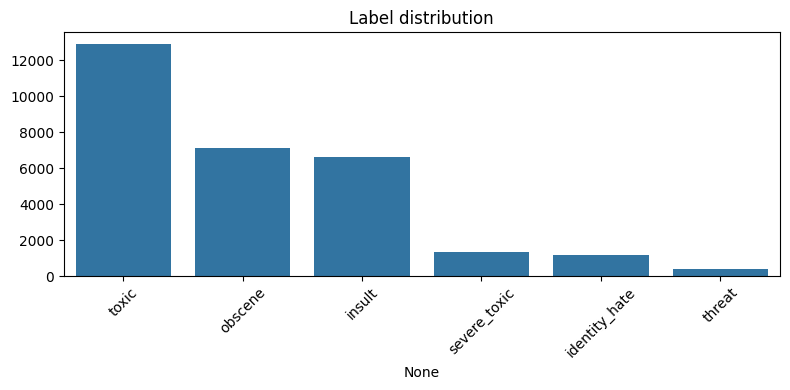

In [11]:
# Label distribution
label_counts = df[LABEL_COLS].sum().sort_values(ascending=False)
print(label_counts)

plt.figure(figsize=(8, 4))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title("Label distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

count    134198.000000
mean        394.647998
std         591.852396
min           5.000000
25%          96.000000
50%         206.000000
75%         435.000000
max        5895.000000
Name: length, dtype: float64


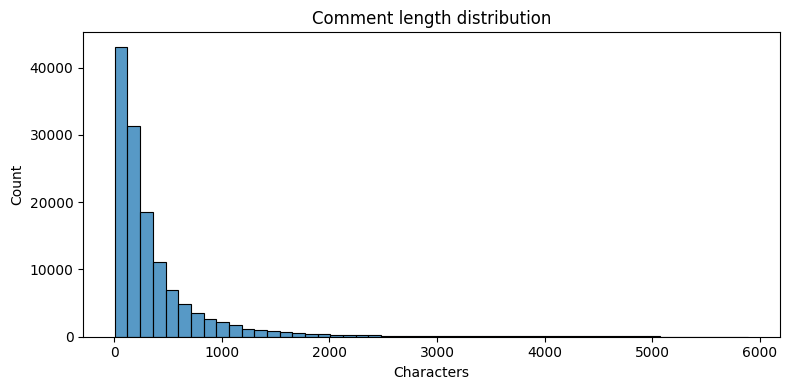

In [12]:
# Comment length distribution
df["length"] = df["comment_text"].astype(str).apply(len)
print(df["length"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df["length"], bins=50)
plt.title("Comment length distribution")
plt.xlabel("Characters")
plt.tight_layout()
plt.show()

In [13]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)          # remove URLs
    text = re.sub(r"\[.*?\]", " ", text)                  # remove [..]
    text = re.sub(r"[^a-z0-9\s!?.,']", " ", text)         # keep basic punctuation
    text = re.sub(r"\s+", " ", text).strip()              # collapse whitespace
    return text

df["clean_text"] = df["comment_text"].apply(clean_text)
df[["comment_text", "clean_text"]].head(10)

,comment_text,clean_text
0,Explanation\nWhy the edits made under my usern...,explanation why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,d'aww! he matches this background colour i'm s...
2,"Hey man, I'm really not trying to edit war. It...","hey man, i'm really not trying to edit war. it..."
3,"""\nMore\nI can't make any real suggestions on ...",more i can't make any real suggestions on impr...
4,"You, sir, are my hero. Any chance you remember...","you, sir, are my hero. any chance you remember..."
5,"""\n\nCongratulations from me as well, use the ...","congratulations from me as well, use the tools..."
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,cocksucker before you piss around on my work
7,Your vandalism to the Matt Shirvington article...,your vandalism to the matt shirvington article...
8,Sorry if the word 'nonsense' was offensive to ...,sorry if the word 'nonsense' was offensive to ...
9,alignment on this subject and which are contra...,alignment on this subject and which are contra...


In [14]:
# Clean and drop bad rows
df["clean_text"] = df["comment_text"].apply(clean_text)

# Drop empty cleaned rows
df = df[df["clean_text"].str.strip().astype(bool)].reset_index(drop=True)

# Drop absurdly long comments (8192 chars blows up memory & gradients)
df = df[df["clean_text"].str.len() <= 5000].reset_index(drop=True)

print("After cleaning:", df.shape)

After cleaning: (134162, 10)


In [15]:
X = df["clean_text"].values
y = df[LABEL_COLS].values.astype("float32")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, shuffle=True
)

print("Train:", X_train.shape, "Val:", X_val.shape)

Train: (114037,) Val: (20125,)


In [16]:
MAX_WORDS = 60000      # vocabulary size
MAX_LEN   = 200        # sequence length
EMBED_DIM = 128

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq   = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_val_pad   = pad_sequences(X_val_seq,   maxlen=MAX_LEN, padding="post", truncating="post")



print("Padded train:", X_train_pad.shape)
print("Padded val  :", X_val_pad.shape)

Padded train: (114037, 200)
Padded val  : (20125, 200)


In [17]:
def build_model(max_words, max_len, embed_dim, num_labels):
    inp = Input(shape=(max_len,), name="input_ids")

    emb = Embedding(
        input_dim=max_words,
        output_dim=embed_dim,
        mask_zero=False,          # ✅ CHANGED — avoids NaN with BiLSTM + GlobalMaxPooling
        name="embedding"
    )(inp)

    x = Bidirectional(LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.0))(emb)
    x = Bidirectional(LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.0))(x)

    avg_pool = tf.keras.layers.GlobalAveragePooling1D()(x)
    max_pool = GlobalMaxPooling1D()(x)
    concat   = Concatenate()([avg_pool, max_pool])

    x = Dense(128, activation="relu",
              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(concat)
    x = Dropout(0.4)(x)
    x = Dense(64, activation="relu",
              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = Dropout(0.3)(x)

    out = Dense(num_labels, activation="sigmoid", name="labels")(x)

    model = Model(inputs=inp, outputs=out)
    model.compile(
        loss="binary_crossentropy",
        # ✅ CHANGED: lower LR + gradient clipping
        optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4, clipnorm=1.0),
        metrics=[tf.keras.metrics.AUC(name="auc", multi_label=True, num_labels=num_labels)]
    )
    return model

model = build_model(MAX_WORDS, MAX_LEN, EMBED_DIM, len(LABEL_COLS))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 128)  │  7,680,000 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 200, 128)  │     98,816 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 200, 128)  │     98,816 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ bidirectional_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ bidirectional_1[… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     32,896 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ labels (Dense)      │ (None, 6)         │        390 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,919,174 (30.21 MB)

 Trainable params: 7,919,174 (30.21 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
EPOCHS = 6
BATCH_SIZE = 256

callbacks = [
    tf.keras.callbacks.TerminateOnNaN(),   # ✅ ADDED — kills training instantly if NaN appears
    EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=1, min_lr=1e-6),
    ModelCheckpoint("best_toxic_model.keras", monitor="val_auc",
                    mode="max", save_best_only=True)
]

history = model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/6
446/446 ━━━━━━━━━━━━━━━━━━━━ 49s 81ms/step - auc: 0.6552 - loss: 0.1939 - val_auc: 0.9358 - val_loss: 0.0950 - learning_rate: 2.0000e-04
Epoch 2/6
446/446 ━━━━━━━━━━━━━━━━━━━━ 74s 77ms/step - auc: 0.9387 - loss: 0.0805 - val_auc: 0.9523 - val_loss: 0.0690 - learning_rate: 2.0000e-04
Epoch 3/6
446/446 ━━━━━━━━━━━━━━━━━━━━ 43s 81ms/step - auc: 0.9599 - loss: 0.0633 - val_auc: 0.9585 - val_loss: 0.0639 - learning_rate: 2.0000e-04
Epoch 4/6
446/446 ━━━━━━━━━━━━━━━━━━━━ 40s 80ms/step - auc: 0.9667 - loss: 0.0566 - val_auc: 0.9564 - val_loss: 0.0640 - learning_rate: 2.0000e-04
Epoch 5/6
446/446 ━━━━━━━━━━━━━━━━━━━━ 36s 80ms/step - auc: 0.9700 - loss: 0.0516 - val_auc: 0.9594 - val_loss: 0.0618 - learning_rate: 1.0000e-04
Epoch 6/6
446/446 ━━━━━━━━━━━━━━━━━━━━ 36s 82ms/step - auc: 0.9712 - loss: 0.0496 - val_auc: 0.9548 - val_loss: 0.0643 - learning_rate: 1.0000e-04


In [19]:
# Load best weights
model.load_weights("best_toxic_model.keras")

val_preds = model.predict(X_val_pad, batch_size=256)

print("\nPer-label ROC-AUC on validation set:")
for i, col in enumerate(LABEL_COLS):
    auc = roc_auc_score(y_val[:, i], val_preds[:, i])
    print(f"  {col:15s}: {auc:.4f}")

print("\nMean ROC-AUC:",
      np.mean([roc_auc_score(y_val[:, i], val_preds[:, i]) for i in range(len(LABEL_COLS))]))

79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step

Per-label ROC-AUC on validation set:
  toxic          : 0.9715
  severe_toxic   : 0.9870
  obscene        : 0.9878
  threat         : 0.9456
  insult         : 0.9821
  identity_hate  : 0.9651

Mean ROC-AUC: 0.9731767808757509


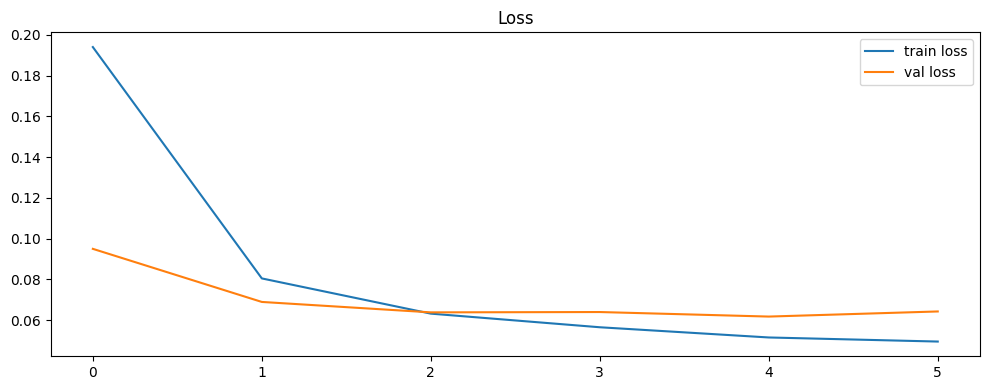

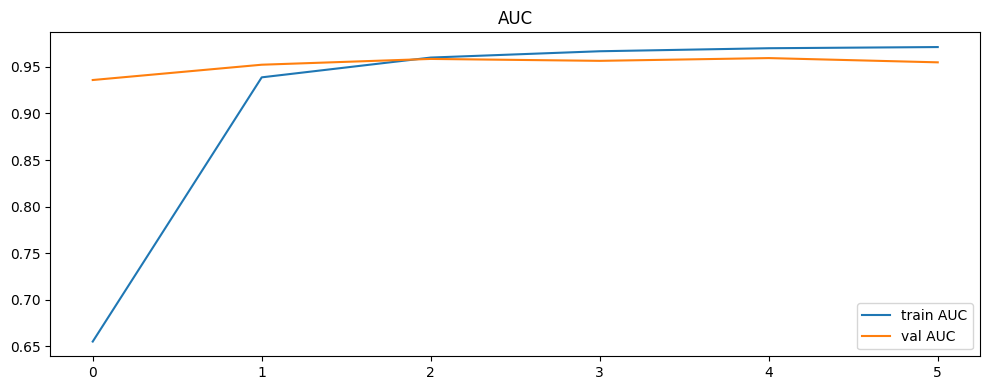

In [20]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.title("Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(history.history["auc"], label="train AUC")
plt.plot(history.history["val_auc"], label="val AUC")
plt.title("AUC")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
import pickle

# Save the trained model in .h5 (Keras) format
model.save("toxic_comment_model.h5")
print("Saved model -> toxic_comment_model.h5")

# Save the tokenizer so you can preprocess new text the same way
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
print("Saved tokenizer -> tokenizer.pkl")

# Optionally also save as .pkl (weights + config) for pure-python loading
model.save("toxic_comment_model.keras")   # newer Keras format
print("Saved model -> toxic_comment_model.keras")

Saved model -> toxic_comment_model.h5
Saved tokenizer -> tokenizer.pkl
Saved model -> toxic_comment_model.keras


In [22]:
def predict_toxicity(texts, model, tokenizer, max_len=MAX_LEN):
    cleaned = [clean_text(t) for t in texts]
    seqs = tokenizer.texts_to_sequences(cleaned)
    pads = pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post")
    preds = model.predict(pads, verbose=0)
    return pd.DataFrame(preds, columns=LABEL_COLS, index=texts)

samples = [
    "You are an idiot and I hate you!",
    "Thanks for the helpful explanation, much appreciated.",
    "I will find you and hurt you."
]

result = predict_toxicity(samples, model, tokenizer)
print(result.round(3))

                                                    toxic  severe_toxic  \
You are an idiot and I hate you!                    0.979         0.138   
Thanks for the helpful explanation, much apprec...  0.001         0.000   
I will find you and hurt you.                       0.453         0.003   

                                                    obscene  threat  insult  \
You are an idiot and I hate you!                      0.887   0.041   0.742   
Thanks for the helpful explanation, much apprec...    0.000   0.000   0.000   
I will find you and hurt you.                         0.048   0.007   0.078   

                                                    identity_hate  
You are an idiot and I hate you!                            0.107  
Thanks for the helpful explanation, much apprec...          0.000  
I will find you and hurt you.                               0.014  


In [24]:
import pickle
import tensorflow as tf
from tensorflow.keras.models import load_model

# Load model architecture and weights, but not the saved optimizer
model = load_model(
    "toxic_comment_model.keras",
    compile=False
)

# Load the existing tokenizer
with open("tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

print("Model and tokenizer loaded successfully!")

Model and tokenizer loaded successfully!


In [25]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4,
        clipnorm=1.0
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [26]:
predictions = model(X_train_pad[:32], training=False)

print("Predictions contain NaN:",
      tf.reduce_any(tf.math.is_nan(predictions)).numpy())

print("Predictions contain Inf:",
      tf.reduce_any(tf.math.is_inf(predictions)).numpy())

Predictions contain NaN: False
Predictions contain Inf: False
